In [1]:
%pip -q install ISLP

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

In [3]:
hitters = load_data('Hitters')
print('Original shape:', hitters.shape)
display(hitters.head())
print('Missing values:')
print(hitters.isna().sum().sort_values())

Original shape: (322, 20)


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,293,66,1,30,29,14,1,293,66,1,30,29,14,A,E,446,33,20,NaN,A
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
4,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N


Missing values:
AtBat         0
Hits          0
HmRun         0
Runs          0
RBI           0
Walks         0
Years         0
CAtBat        0
CHits         0
CHmRun        0
CRuns         0
CRBI          0
CWalks        0
League        0
Division      0
PutOuts       0
Assists       0
Errors        0
NewLeague     0
Salary       59
dtype: int64


In [5]:
hitters = hitters.dropna(subset=['Salary']).copy()

X = hitters.drop(columns='Salary')
y = hitters['Salary']

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
category_cols = X.select_dtypes(exclude=np.number).columns.tolist()
print(category_cols)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=10
)

['League', 'Division', 'NewLeague']


In [12]:
def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numeric_cols),
            ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), category_cols)
            ])

In [19]:
alpha_examples = [ 0.1, 10, 100]
rows = []
for a in alpha_examples:
      pipe = Pipeline([
          ('preprocess', make_preprocessor()),
          ('model', Lasso(alpha=a, max_iter=3000,random_state=10))
      ])
      pipe.fit(X_train, y_train)

      coefs = pipe.named_steps['model'].coef_

      rows.append({
          'Model': 'Lasso', 'alpha': a,
          'Nonzero coefficients': int(np.sum(np.abs(coefs) > 1e-6)),
          'Coefficient L1 size': float(np.sum(np.abs(coefs))),
          'Training RMSE': np.sqrt(mean_squared_error(y_train, pipe.predict(X_train))),
          'Test RMSE' : np.sqrt(mean_squared_error(y_test, pipe.predict(X_test)))
      })
alpha_table = pd.DataFrame(rows)
display(alpha_table.round(2))

,Model,alpha,Nonzero coefficients,Coefficient L1 size,Training RMSE,Test RMSE
0,Lasso,0.1,19,3498.93,279.60,390.08
1,Lasso,10.0,8,542.95,303.00,381.10
2,Lasso,100.0,4,232.10,343.24,397.94


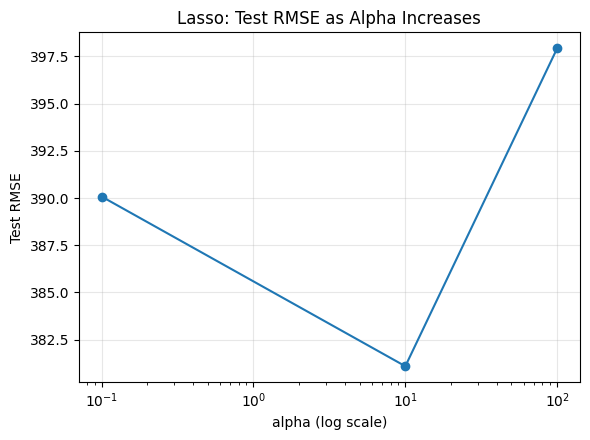

In [29]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.semilogx(alpha_table['alpha'], alpha_table['Test RMSE'], marker='o')
ax.set_title('Lasso: Test RMSE as Alpha Increases')
ax.set_xlabel('alpha (log scale)')
ax.set_ylabel('Test RMSE')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

*PART 2 QUESTIONS*

*1. Which α produces the lowest test RMSE among the three values?*

An alpha of 10 productes the lowest test RMSE among the three values.

*2. Which α appears to cause the most underfitting? Explain using bias.*

The alpha value of 100 causes the most underfitting. Penalizing the model by dropping too many features leads to high bias. This means that the model can not identify relevant patterns as the model is too simple.

*3. Why might a model with higher training RMSE produce lower test RMSE?*

While a model with higher training RMSE may miss some details on training data, it will learn overall patterns. Therefore, when it is introduced to the testing data, it will perform better as it will be able to handle noise better, which results in a lower test RMSE.


In [34]:
feature_names = pipe.named_steps['preprocess'].get_feature_names_out()

coef_table = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': pipe.named_steps['model'].coef_
})

dropped_features = coef_table[abs(coef_table['Coefficient']) < 1e-6]
print("Dropped Features:")
display(coef_table.round(2))

Dropped Features:


,Feature,Coefficient
0,num__AtBat,0.00
1,num__Hits,54.02
2,num__HmRun,0.00
3,num__Runs,0.00
4,num__RBI,0.00
5,num__Walks,29.75
6,num__Years,0.00
7,num__CAtBat,0.00
8,num__CHits,0.00
9,num__CHmRun,0.00


*Using your results from Part 1:*


*1. Identify two predictors that Lasso sets to zero at α = 100.*

Two predictors that Lasso sets to zero at an alpha value of 100 are num_HmRun and num_Runs.

*2. Does setting their coefficients to zero prove that these predictors have no relationship with salary? Explain.*

Setting their coefficients to zero does not prove that these predictors have no relationship with salary. An alpha value of 100 is strict, meaning the model forces many coefficients to 0 to keep things as simple as possible. This may be done due to multicollinearity with other features.

*3. If two models have very similar test RMSE but one uses fewer predictors, which would you prefer? Explain your answer in terms of interpretability and predictive performance*

I would prefer the model with fewer predictors. The predictive performance is likely equal if their test RMSE are similar. Additionally, this model would be easier to interpret as their are less variables to deal with.

*Scenario A: A researcher has data from 80 patients with 200 medical measurements. The goal is to identify a small number of measurements that may be useful for predicting disease severity.*

Lasso would be the best model for this. Only a few of the medical measurements actually matter. Lasso would drop the measurements that have no real significance, therefore reducing model complexity.

*Scenario B: A company wants to predict employee salaries using 40 predictors. Many predictors are strongly correlated, and the company believes most contain useful information. Keeping all predictors is not a concern.*

Ridge would be the best model for this. The 40 predictors are strongly correlated and contain useful information, so none of the features should be dropped. Ridge would shrink the coefficients across all the features, thus preserving their importance.

*Scenario C: A researcher has 10,000 observations and only three predictors. The
relationship appears approximately linear, and the researcher wants a simple model that is easy to interpret.*

Ordinary Linear Regression makes the most sense as the abundance of observations and the few features generally means the chances of overfitting is low. Adding Lasso or Ridge would be unnecessary. Ordinary Linear Regression keeps the model complexity the lowest.

*Scenario D: A company has 500 observations and 25 predictors. It is unclear how many predictors are useful or how strongly they are correlated. The company wants the most accurate predictions possible.*

There is not enough information to choose the most optimal model. It is unclear how many features are actually useful and how strongly they are correlated, meaning we can not decide whether we want to drop some features or keep all of them. As for Ordinary Linear Regression, the risk of overfitting is high as the model has no way to get rid of noisy variables, if there are any.